# Imputación de huecos largos del rendimiento horario (experimento ampliado)

En este cuaderno justificamos con datos dos decisiones, que son imputar solo los huecos de hasta una hora y estimar los
días pasados sin telemetría con el método físico ($Y_r$ observado por el $PR$ reciente) en la energía del mes. El
experimento del cuaderno por localidad (sección C) compara técnicas en la potencia de cinco minutos con huecos de 15
minutos a 3 horas, pero no dice qué pasa con huecos de horas o días, que son los que aparecen cuando falla la
transmisión. Por eso aquí borramos tramos de 1 hora a 3 días en la serie horaria de $Y_f$ y los reconstruimos con seis
técnicas.

Usamos la unidad principal de cada grupo, según `resultados.json` (la escribe el cuaderno por localidad), y su serie
horaria procesada con `tfm.pipeline.procesar`, en el régimen vigente y hasta el corte del modelado
(`config.FIN_MODELADO`), así que ningún dato posterior al corte entra en la decisión y los datos de `datos/` solo se
leen. El cuaderno deja `resultados/experimento_imputacion_ampliado_<grupo>.csv`, la figura `<grupo>_imputacion_ampliada`
(PNG y PDF, con sus valores en CSV) y la clave `localidades.<grupo>.datos.imputacion_ampliada` de `resultados.json`.
Sus parámetros son `GRUPOS`, el número de huecos por duración (`N`), si se registra en `resultados.json` (`REGISTRAR`) y
si se exportan las figuras (`GUARDAR_FIGURAS`).

In [1]:
# Parámetros (papermill los reemplaza)
GRUPOS = ["G01", "G02"]
N = 150                    # huecos artificiales por duración
REGISTRAR = True           # escribir el resultado en resultados.json
GUARDAR_FIGURAS = True     # exportar la figura a resultados/figuras

In [2]:
import os, sys, warnings
from pathlib import Path
if not Path("tfm").is_dir() and Path("../tfm").is_dir():
    os.chdir("..")     # copia ejecutada abierta desde notebooks/ejecutados: se trabaja desde notebooks/
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown as MarkdownIPython
def Markdown(texto):                  # cifras con coma decimal, como en el documento y las figuras
    return MarkdownIPython(gr.texto_es(texto))
def miles(n):                         # separador de miles con espacio: 12 345 (la coma sería decimal)
    return f"{int(n):,}".replace(",", " ")
from statsmodels.tsa.statespace.sarimax import SARIMAX

from tfm import config, graficos as gr, nomenclatura as nom, particiones as part, pipeline, resultados as res
gr.estilo()
DURACIONES = {"1 h": 1, "2 h": 2, "6 h": 6, "12 h": 12, "1 día": 24, "3 días": 72}
METODOS = ["lineal", "cielo_despejado", "estacional_anterior", "estacional_promedio", "fisico", "kalman_sarima"]
display(Markdown(f"Corte del modelado: datos hasta el día anterior a **{config.FIN_MODELADO}**; semilla {config.SEMILLA}."))

Corte del modelado: datos hasta el día anterior a **2026-11-01**; semilla 37.

## 1. Diseño del experimento

Sobre la serie horaria de $Y_f$ de la unidad principal de cada grupo se borran al azar (semilla 37) hasta `N` tramos
de 1, 2, 6 y 12 horas y de 1 y 3 días. Un tramo es elegible si todas sus horas de sol y los dos días anteriores y
posteriores están observados: la hora observada tiene al menos el 75 % de sus lecturas de cinco minutos medidas
(exigir el 100 % no deja tramos de varios días), no está en falla ni recortada y está en el régimen vigente. De
noche el valor es 0, un dato físico. Las técnicas son:

| Técnica | Cómo reconstruye el tramo |
|---|---|
| Interpolación lineal | Recta entre las horas anterior y posterior al hueco (0 de noche) |
| Índice de cielo despejado | Interpola $k^* = Y_f / Y_{r,cs}$ entre la última hora de sol antes y la primera después, y lo multiplica por $Y_{r,cs}$ |
| Misma hora del día anterior | El valor del último día completo antes del hueco |
| Promedio del día anterior y posterior | Media de la misma hora del día anterior y del posterior |
| Físico | $Y_r$ observado de cada hora por el $PR$ de los 30 días anteriores al hueco (no usa datos posteriores) |
| Suavizado de Kalman | SARIMA(1,0,1)(1,0,1)$_{24}$ con los parámetros del entrenamiento, suavizado en una ventana de ±7 días |

El error (MAE, RMSE, MBE y rMAE, el MAE relativo a la media observada) se mide solo en las horas de sol del hueco.
**Regla de decisión, fijada antes de mirar el resultado:** se imputa hasta la duración en que la técnica más simple
que empata con la mejor (menos de medio punto de rMAE) mantiene un rMAE comparable al del experimento de cinco
minutos; los huecos más largos no se imputan y los días pasados sin datos se estiman con el método que no necesita
datos posteriores al hueco, porque en la operación el día siguiente todavía no existe.

In [3]:
def serie_unidad(grupo):
    r = res.cargar()["localidades"][grupo]
    unidad = r["conclusiones"]["unidad_principal"]
    t = nom.tabla()
    uuid = t.loc[t["codigo"] == unidad, "deviceuuid"].iloc[0]
    # Lectura hasta el corte (fecha local exclusiva): nada posterior entra en la decisón
    u = pipeline.procesar(grupo, uuid, config.INICIO_DATOS, config.FIN_MODELADO, refrescar=False, corte=config.FIN_MODELADO)
    h = u.horario.loc[u.horario.index <= config.CORTE_UTC]
    obs = (h["frac_imputada"].fillna(1) <= 0.25) & h["en_regimen"] & h["yf"].notna() & h["yr"].notna()
    return unidad, h, obs.to_numpy()


def parametros_kalman(h, obs):
    # SARIMA ajustado con los últimos 120 días del entrenamiento (de noche el valor es 0)
    en_tr = part.etiquetar(h.index).to_numpy() == "entrenamiento"
    sol = h["yr_cs"].to_numpy() > 0.05
    y = h["yf"].where(obs | ~sol)[en_tr].iloc[-24 * 120:]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = SARIMAX(y.to_numpy(), order=(1, 0, 1), seasonal_order=(1, 0, 1, 24), enforce_stationarity=False,
                    enforce_invertibility=False).fit(disp=False, maxiter=200)
    return m.params


def experimento(h, obs, params):
    rng = np.random.default_rng(config.SEMILLA)
    yf, yr, yr_cs = (h[c].to_numpy(dtype=float) for c in ("yf", "yr", "yr_cs"))
    sol = yr_cs > 0.05
    disponible = obs | ~sol
    n = len(yf)
    filas = []
    for nombre, m in DURACIONES.items():
        # Hueco [i, i + m): todas sus horas y 2 días antes y después disponibles, y al menos una hora de sol
        largo = m + 2 * 48
        conv = np.convolve(disponible.astype(int), np.ones(largo, dtype=int), mode="valid")
        inicios = np.where(conv == largo)[0] + 48
        inicios = inicios[(inicios + m + 48 <= n) & np.array([sol[i:i + m].any() for i in inicios])] if len(inicios) else inicios
        if len(inicios) == 0:
            continue
        elegidos = np.sort(rng.choice(inicios, size=min(N, len(inicios)), replace=False))
        err, verdad_total = {k: [] for k in METODOS}, []
        for i in elegidos:
            g, t = slice(i, i + m), np.arange(i, i + m)
            dentro, a, z = sol[g], i - 1, i + m
            verdad = yf[g][dentro]
            est = {"lineal": np.where(sol[g], yf[a] + (yf[z] - yf[a]) * (t - a) / (z - a), 0.0)}
            antes = np.flatnonzero(sol[:i] & obs[:i])
            despues = i + m + np.flatnonzero(sol[i + m:] & obs[i + m:])
            if len(antes) and len(despues):
                ia, iz = antes[-1], despues[0]
                k = yf[ia] / yr_cs[ia] + (yf[iz] / yr_cs[iz] - yf[ia] / yr_cs[ia]) * (t - ia) / (iz - ia)
                est["cielo_despejado"] = np.clip(k, 0, 1.5) * yr_cs[g]
            else:
                est["cielo_despejado"] = np.full(m, np.nan)
            d_ant = int(np.ceil(m / 24)) * 24
            ant = yf[t - d_ant] if i - d_ant >= 0 else np.full(m, np.nan)
            pos = yf[t + d_ant] if i + m + d_ant <= n else np.full(m, np.nan)
            est["estacional_anterior"] = ant
            est["estacional_promedio"] = np.nanmean(np.vstack([ant, pos]), axis=0)
            v = slice(max(0, i - 30 * 24), i)
            ok = obs[v] & sol[v]
            pr30 = yf[v][ok].sum() / yr[v][ok].sum() if yr[v][ok].sum() > 0 else np.nan
            est["fisico"] = yr[g] * pr30
            w = slice(max(0, i - 7 * 24), min(n, i + m + 7 * 24))
            yw = np.where(obs[w] | ~sol[w], yf[w], np.nan)
            yw[(i - w.start):(i - w.start + m)] = np.nan
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                senal = SARIMAX(yw, order=(1, 0, 1), seasonal_order=(1, 0, 1, 24), enforce_stationarity=False,
                                enforce_invertibility=False).smooth(params).smoother_results.smoothed_forecasts[0]
            est["kalman_sarima"] = np.where(sol[g], np.clip(senal[(i - w.start):(i - w.start + m)], 0, None), 0.0)
            for k in METODOS:
                err[k].append(est[k][dentro] - verdad)
            verdad_total.append(verdad)
        media = float(np.mean(np.concatenate(verdad_total)))
        for k in METODOS:
            e = np.concatenate(err[k])
            filas.append({"duracion": nombre, "horas": m, "metodo": k, "huecos": len(elegidos), "horas_de_sol": int(np.isfinite(e).sum()),
                          "mae": float(np.nanmean(np.abs(e))), "rmse": float(np.sqrt(np.nanmean(e ** 2))),
                          "mbe": float(np.nanmean(e)), "rmae_pct": 100 * float(np.nanmean(np.abs(e))) / media})
    return pd.DataFrame(filas)

## 2. Resultado por grupo

In [4]:
RESULTADOS = {}
for grupo in GRUPOS:
    unidad, h, obs = serie_unidad(grupo)
    t = experimento(h, obs, parametros_kalman(h, obs)).assign(unidad=unidad)
    t.to_csv(config.DIR_RESULTADOS / f"experimento_imputacion_ampliado_{grupo}.csv", index=False)
    RESULTADOS[grupo] = t
    tabla = t.pivot(index="metodo", columns="duracion", values="rmae_pct")[list(DURACIONES)]
    display(Markdown(f"**{grupo} ({unidad}): rMAE (%) en las horas de sol del hueco**, {miles(obs.sum())} horas observadas hasta el corte"))
    display(tabla.round(1))

C:\Users\leons\AppData\Local\Temp\ipykernel_35428\1409943430.py:59: RuntimeWarning: Mean of empty slice
  est["estacional_promedio"] = np.nanmean(np.vstack([ant, pos]), axis=0)


C:\Users\leons\AppData\Local\Temp\ipykernel_35428\1409943430.py:59: RuntimeWarning: Mean of empty slice
  est["estacional_promedio"] = np.nanmean(np.vstack([ant, pos]), axis=0)


C:\Users\leons\AppData\Local\Temp\ipykernel_35428\1409943430.py:59: RuntimeWarning: Mean of empty slice
  est["estacional_promedio"] = np.nanmean(np.vstack([ant, pos]), axis=0)


C:\Users\leons\AppData\Local\Temp\ipykernel_35428\1409943430.py:59: RuntimeWarning: Mean of empty slice
  est["estacional_promedio"] = np.nanmean(np.vstack([ant, pos]), axis=0)


C:\Users\leons\AppData\Local\Temp\ipykernel_35428\1409943430.py:59: RuntimeWarning: Mean of empty slice
  est["estacional_promedio"] = np.nanmean(np.vstack([ant, pos]), axis=0)


C:\Users\leons\AppData\Local\Temp\ipykernel_35428\1409943430.py:59: RuntimeWarning: Mean of empty slice
  est["estacional_promedio"] = np.nanmean(np.vstack([ant, pos]), axis=0)


... (122 outputs left out)

C:\Users\leons\AppData\Local\Temp\ipykernel_35428\1409943430.py:59: RuntimeWarning: Mean of empty slice
  est["estacional_promedio"] = np.nanmean(np.vstack([ant, pos]), axis=0)


C:\Users\leons\AppData\Local\Temp\ipykernel_35428\1409943430.py:59: RuntimeWarning: Mean of empty slice
  est["estacional_promedio"] = np.nanmean(np.vstack([ant, pos]), axis=0)


**G02 (P04I0202): rMAE (%) en las horas de sol del hueco**, 8 841 horas observadas hasta el corte

duracion,1 h,2 h,6 h,12 h,1 día,3 días
metodo,,,,,,
cielo_despejado,11.0,14.0,21.8,24.1,26.2,26.5
estacional_anterior,23.6,23.2,21.9,21.8,23.1,28.4
estacional_promedio,18.9,18.5,18.8,18.4,18.5,24.4
fisico,21.1,20.2,22.9,21.3,22.1,22.3
kalman_sarima,12.1,15.4,17.6,17.3,18.0,18.6
lineal,12.7,17.2,34.7,61.3,81.2,76.6


## 3. Figura: las dos escalas del experimento

A la izquierda, el experimento del cuaderno por localidad sobre la potencia de cinco minutos (huecos de 15 minutos a
3 horas); a la derecha, este experimento sobre el $Y_f$ horario (huecos de 1 hora a 3 días). Cada técnica tiene el
mismo color, marcador y tipo de línea en los dos paneles.

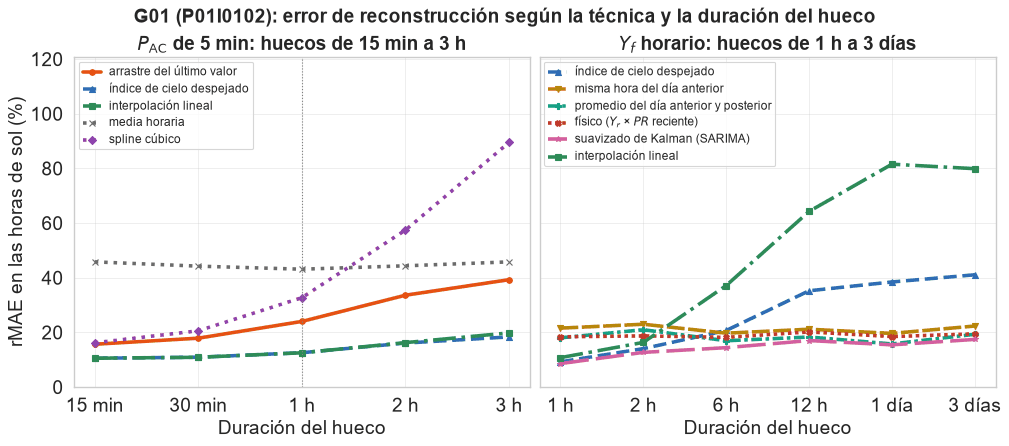

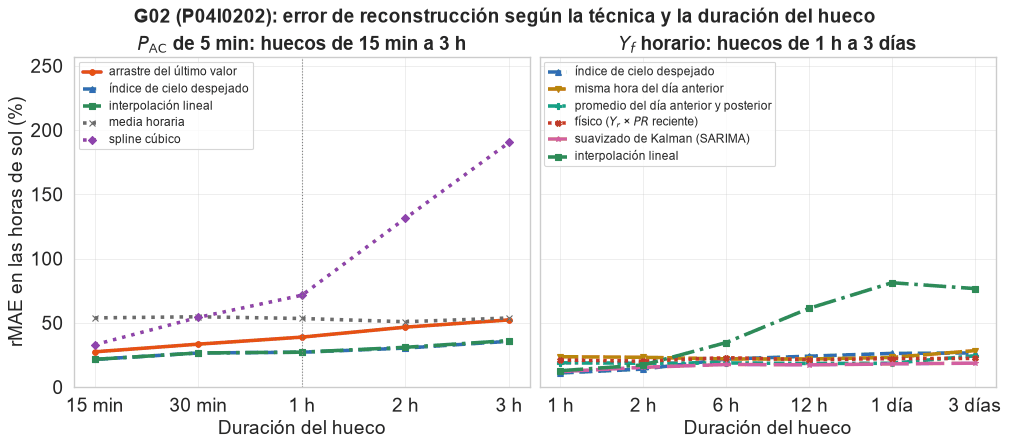

In [5]:
NOMBRE_METODO = {"lineal": "interpolación lineal", "cielo_despejado": "índice de cielo despejado",
                 "estacional_anterior": "misma hora del día anterior", "estacional_promedio": "promedio del día anterior y posterior",
                 "fisico": "físico (Yr × PR reciente)", "kalman_sarima": "suavizado de Kalman (SARIMA)"}
NOMBRE_TECNICA_5MIN = {"lineal": "interpolación lineal", "cielo_despejado": "índice de cielo despejado",
                       "arrastre": "arrastre del último valor", "spline_cubico": "spline cúbico", "media_horaria": "media horaria"}

def dibujar(grupo, t):
    unidad = t["unidad"].iloc[0]
    tabla = t.pivot(index="metodo", columns="duracion", values="rmae_pct")[list(DURACIONES)]
    ruta_5min = config.DIR_DATOS_FIGURAS / f"{grupo.lower()}_experimento_imputacion.csv"
    corta = pd.read_csv(ruta_5min, index_col=0) if ruta_5min.exists() else None
    f, axes = plt.subplots(1, 2 if corta is not None else 1, figsize=(12.5, 5.5) if corta is not None else (9, 5.25),
                           sharey=True, squeeze=False)
    axes = axes[0]
    paneles = ([(corta.T, NOMBRE_TECNICA_5MIN, r"$P_{\mathrm{AC}}$ de 5 min: huecos de 15 min a 3 h", "1h")] if corta is not None else [])
    paneles.append((tabla, NOMBRE_METODO, "Yf horario: huecos de 1 h a 3 días", None))
    todas = [m for m in dict.fromkeys([*(corta.columns if corta is not None else []), *tabla.index]) if m != "media_horaria"]
    estilo = dict(zip(todas, gr.estilos_series(len(todas))))
    estilo["media_horaria"] = {"color": config.COLOR_NEUTRO, "marker": "x", "linestyle": ":"}
    for ax, (tab, nombres, titulo, marca) in zip(axes, paneles):
        x = np.arange(tab.shape[1])
        for metodo, fila in tab.iterrows():
            e = estilo[metodo]
            ax.plot(x, fila.to_numpy(), marker=e["marker"], ms=5, lw=3.2, color=e["color"], linestyle=e["linestyle"],
                    label=nombres.get(metodo, metodo.replace("_", " ")))
        ax.set_xticks(x, [c.replace("min", " min").replace("h", " h") if c[0].isdigit() and " " not in c else c for c in tab.columns])
        if marca in tab.columns:
            ax.axvline(list(tab.columns).index(marca), color="grey", ls=":", lw=1)
        ax.set_xlabel("Duración del hueco"); ax.set_title(titulo)
        ax.legend(fontsize=8.5, loc="upper left")
    # Margen arriba para la leyenda, dentro del eje y arriba a la izquierda, donde las curvas no llegan
    tope = max(np.nanmax(tab.to_numpy(dtype=float)) for tab, *_ in paneles)
    axes[0].set_ylim(0, 1.35 * tope); axes[0].set_ylabel("rMAE en las horas de sol (%)")
    f.suptitle(f"{grupo} ({unidad}): error de reconstrucción según la técnica y la duración del hueco", fontweight="bold")
    datos_f = pd.concat({"potencia_5min": corta, "yf_horario": tabla.T}) if corta is not None else tabla
    gr.guardar(f, f"{grupo.lower()}_imputacion_ampliada", GUARDAR_FIGURAS, datos_f, leyenda_dentro=True, partir_titulos=False)
    plt.show()

for grupo, t in RESULTADOS.items():
    dibujar(grupo, t)

## 4. Decisión y registro

In [6]:
for grupo, t in RESULTADOS.items():
    tabla = t.pivot(index="metodo", columns="duracion", values="rmae_pct")[list(DURACIONES)]
    mejor_1h = tabla["1 h"].idxmin()
    empate_1h = [m for m in tabla.index if tabla.loc[m, "1 h"] - tabla.loc[mejor_1h, "1 h"] < 0.5]
    largos = ["1 día", "3 días"]
    mejor_largo = tabla[largos].mean(axis=1).idxmin()
    display(Markdown(
        f"**{grupo}.** A una hora, el menor error es el de {NOMBRE_METODO[mejor_1h]} ({tabla.loc[mejor_1h, '1 h']:.1f} %) y empatan con "
        f"ella (menos de medio punto): {', '.join(NOMBRE_METODO[m] for m in empate_1h)}. La interpolación lineal pasa de "
        f"{tabla.loc['lineal', '1 h']:.1f} % a una hora a {tabla.loc['lineal', '1 día']:.0f} % en un hueco de un día, porque une los "
        f"extremos a través de la noche. En los huecos de uno y tres días el menor error medio es el de {NOMBRE_METODO[mejor_largo]}, "
        f"y el método físico, que no necesita datos posteriores al hueco, da {tabla.loc['fisico', '1 día']:.1f} y "
        f"{tabla.loc['fisico', '3 días']:.1f} %.\n\nPor eso decidimos imputar solo hasta una hora con la técnica más simple del empate y "
        "estimar los días pasados sin datos con el método físico, el único que se puede aplicar el mismo día en la operación."))
    if REGISTRAR:
        res.registrar(f"localidades.{grupo}.datos.imputacion_ampliada",
                      {"unidad": t["unidad"].iloc[0], "rmae_pct": tabla.round(2).to_dict(orient="index"),
                       "mbe": t.pivot(index="metodo", columns="duracion", values="mbe")[list(DURACIONES)].round(5).to_dict(orient="index"),
                       "huecos": t.groupby("duracion")["huecos"].first().to_dict(), "corte": config.FIN_MODELADO})
if REGISTRAR:
    display(Markdown("Resultados registrados en `localidades.<grupo>.datos.imputacion_ampliada`."))

**G01.** A una hora, el menor error es el de suavizado de Kalman (SARIMA) (8,6 %) y empatan con ella (menos de medio punto): suavizado de Kalman (SARIMA). La interpolación lineal pasa de 10,8 % a una hora a 82 % en un hueco de un día, porque une los extremos a través de la noche. En los huecos de uno y tres días el menor error medio es el de suavizado de Kalman (SARIMA), y el método físico, que no necesita datos posteriores al hueco, da 18,5 y 19,5 %.

Por eso decidimos imputar solo hasta una hora con la técnica más simple del empate y estimar los días pasados sin datos con el método físico, el único que se puede aplicar el mismo día en la operación.

**G02.** A una hora, el menor error es el de índice de cielo despejado (11,0 %) y empatan con ella (menos de medio punto): índice de cielo despejado. La interpolación lineal pasa de 12,7 % a una hora a 81 % en un hueco de un día, porque une los extremos a través de la noche. En los huecos de uno y tres días el menor error medio es el de suavizado de Kalman (SARIMA), y el método físico, que no necesita datos posteriores al hueco, da 22,1 y 22,3 %.

Por eso decidimos imputar solo hasta una hora con la técnica más simple del empate y estimar los días pasados sin datos con el método físico, el único que se puede aplicar el mismo día en la operación.

Resultados registrados en `localidades.<grupo>.datos.imputacion_ampliada`.